# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

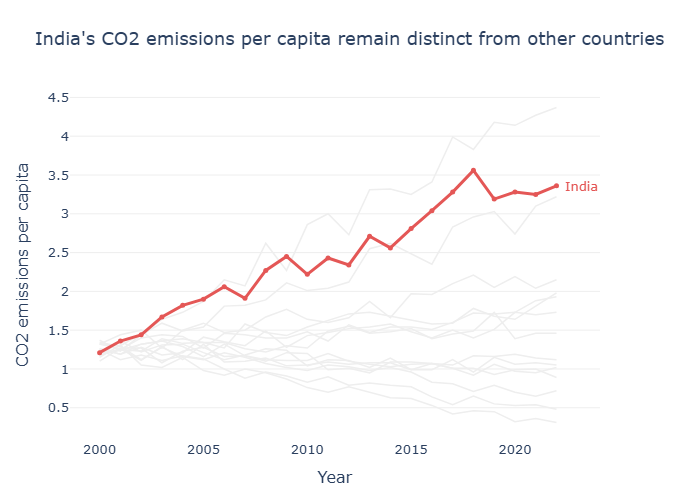

In [7]:


highlight_country = "India"

fig = go.Figure()

# All other countries in light grey
for country in df["Country"].unique():
    if country != highlight_country:
        country_data = df[df["Country"] == country].sort_values("Year")

        fig.add_trace(go.Scatter(
            x=country_data["Year"],
            y=country_data["CO2_per_capita"],
            mode="lines",
            line=dict(color="#EEEEEE", width=1.5),
            showlegend=False,
            hovertemplate=(
                country + "<br>Year: %{x}<br>CO2 per capita: %{y:.2f}"
                "<extra></extra>"
            )
        ))

# Highlight India in colour
india_data = (
    df[df["Country"] == highlight_country]
    .sort_values("Year")
)

fig.add_trace(go.Scatter(
    x=india_data["Year"],
    y=india_data["CO2_per_capita"],
    mode="lines+markers",
    line=dict(color="#E45756", width=3),
    marker=dict(size=5),
    showlegend=False,
    hovertemplate=(
        "India<br>Year: %{x}<br>CO2 per capita: %{y:.2f}"
        "<extra></extra>"
    )
))

# Label India directly at the end of its line
fig.add_annotation(
    x=india_data["Year"].iloc[-1],
    y=india_data["CO2_per_capita"].iloc[-1],
    text="India",
    showarrow=False,
    xshift=25,
    font=dict(size=13, color="#E45756")
)

fig.update_layout(
    title="India's CO2 emissions per capita remain distinct from other countries",
    xaxis_title="Year",
    yaxis_title="CO2 emissions per capita",
    plot_bgcolor="white",
    paper_bgcolor="white",
    font=dict(size=13),
    margin=dict(l=70, r=100, t=90, b=60),
    xaxis=dict(showgrid=False, showline=False),
    yaxis=dict(showgrid=True, gridcolor="#EEEEEE", showline=False),
    height=500
)

fig.show(renderer="png")
 

---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

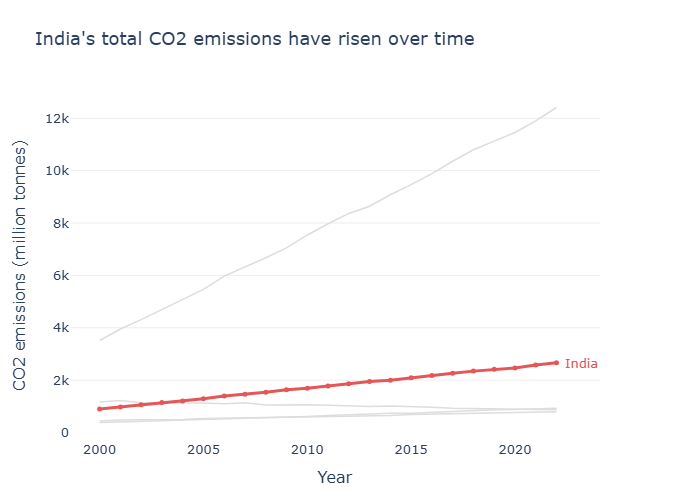

In [8]:
# Task — Multi-series line with highlight


asia_data = df[df["Region"] == "Asia"]
highlight_country = "India"

fig = go.Figure()

# Show other Asian countries in light grey
for country in asia_data["Country"].unique():
    if country != highlight_country:
        country_data = (
            asia_data[asia_data["Country"] == country]
            .sort_values("Year")
        )

        fig.add_trace(go.Scatter(
            x=country_data["Year"],
            y=country_data["CO2_Mt"],
            mode="lines",
            line=dict(color="#DDDDDD", width=1.5),
            showlegend=False,
            hovertemplate=(
                country
                + "<br>Year: %{x}"
                + "<br>CO2 emissions: %{y:.1f} Mt"
                + "<extra></extra>"
            )
        ))

# Highlight India
india_data = (
    asia_data[asia_data["Country"] == highlight_country]
    .sort_values("Year")
)

fig.add_trace(go.Scatter(
    x=india_data["Year"],
    y=india_data["CO2_Mt"],
    mode="lines+markers",
    line=dict(color="#E45756", width=3),
    marker=dict(size=5),
    showlegend=False,
    hovertemplate=(
        "India<br>Year: %{x}"
        "<br>CO2 emissions: %{y:.1f} Mt"
        "<extra></extra>"
    )
))

# Label India at the end of its line
fig.add_annotation(
    x=india_data["Year"].iloc[-1],
    y=india_data["CO2_Mt"].iloc[-1],
    text="India",
    showarrow=False,
    xshift=25,
    font=dict(size=13, color="#E45756")
)

fig.update_layout(
    title="India's total CO2 emissions have risen over time",
    xaxis_title="Year",
    yaxis_title="CO2 emissions (million tonnes)",
    plot_bgcolor="white",
    paper_bgcolor="white",
    font=dict(size=13),
    margin=dict(l=70, r=100, t=90, b=60),
    xaxis=dict(showgrid=False, showline=False),
    yaxis=dict(showgrid=True, gridcolor="#EEEEEE", showline=False),
    height=500
)

fig.show(renderer="png")
 